<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Exploding_Gradient_Scenario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class DeepSigmoidNet(nn.Module):
    def __init__(self, input_size=20, hidden_layers=10, hidden_size=64):
        super().__init__()
        layers = []
        layers.append(nn.Linear(input_size, hidden_size))
        layers.append(nn.Sigmoid())
        for _ in range(hidden_layers - 1):
            layers.append(nn.Linear(hidden_size, hidden_size))
            layers.append(nn.Sigmoid())
        layers.append(nn.Linear(hidden_size, 1))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return self.network(x)
torch.manual_seed(42)
X = torch.randn(100, 20)
y = torch.randn(100, 1)

model = DeepSigmoidNet()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 10
print(f"Starting training on {epochs} epochs...\n")

for epoch in range(1, epochs + 1):
    outputs = model(X)
    loss = criterion(outputs, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(f"Epoch [{epoch}/{epochs}], Loss: {loss.item():.4f}")

Starting training on 10 epochs...

Epoch [1/10], Loss: 1.1462
Epoch [2/10], Loss: 0.7811
Epoch [3/10], Loss: 0.9461
Epoch [4/10], Loss: 0.9364
Epoch [5/10], Loss: 0.8363
Epoch [6/10], Loss: 0.7800
Epoch [7/10], Loss: 0.7897
Epoch [8/10], Loss: 0.8245
Epoch [9/10], Loss: 0.8429
Epoch [10/10], Loss: 0.8335


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
class DeepSigmoidNet(nn.Module):
    def __init__(self, input_size=20, hidden_layers=10, hidden_size=64):
        super().__init__()
        self.layers = nn.ModuleList()

        self.layers.append(nn.Linear(input_size, hidden_size))

        for _ in range(hidden_layers - 1):
            self.layers.append(nn.Linear(hidden_size, hidden_size))

        self.output_layer = nn.Linear(hidden_size, 1)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        for layer in self.layers:
            x = self.activation(layer(x))
        return self.output_layer(x)

torch.manual_seed(42)
X = torch.randn(100, 20)
y = torch.randn(100, 1)

model = DeepSigmoidNet()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 5
for epoch in range(1, epochs + 1):
    outputs = model(X)
    loss = criterion(outputs, y)

    optimizer.zero_grad()
    loss.backward()

    print(f"--- Epoch {epoch} Gradient Magnitudes ---")

    for i, layer in enumerate(model.layers):

        grad_mag = layer.weight.grad.abs().mean().item()
        print(f"Layer {i+1} grad: {grad_mag:.10f}")

    out_grad = model.output_layer.weight.grad.abs().mean().item()
    print(f"Output Layer grad: {out_grad:.10f}")
    print(f"Loss: {loss.item():.4f}\n")

    optimizer.step()

--- Epoch 1 Gradient Magnitudes ---
Layer 1 grad: 0.0000000000
Layer 2 grad: 0.0000000008
Layer 3 grad: 0.0000000060
Layer 4 grad: 0.0000000474
Layer 5 grad: 0.0000004061
Layer 6 grad: 0.0000031630
Layer 7 grad: 0.0000201061
Layer 8 grad: 0.0001699219
Layer 9 grad: 0.0010996128
Layer 10 grad: 0.0090298103
Output Layer grad: 0.6283085942
Loss: 1.1462

--- Epoch 2 Gradient Magnitudes ---
Layer 1 grad: 0.0000000001
Layer 2 grad: 0.0000000003
Layer 3 grad: 0.0000000016
Layer 4 grad: 0.0000000103
Layer 5 grad: 0.0000000754
Layer 6 grad: 0.0000004496
Layer 7 grad: 0.0000028710
Layer 8 grad: 0.0000226111
Layer 9 grad: 0.0001325822
Layer 10 grad: 0.0008379848
Output Layer grad: 0.0606058612
Loss: 0.7811

--- Epoch 3 Gradient Magnitudes ---
Layer 1 grad: 0.0000000001
Layer 2 grad: 0.0000000011
Layer 3 grad: 0.0000000074
Layer 4 grad: 0.0000000518
Layer 5 grad: 0.0000003979
Layer 6 grad: 0.0000023714
Layer 7 grad: 0.0000167624
Layer 8 grad: 0.0001495167
Layer 9 grad: 0.0011523499
Layer 10 grad: 

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

class DeepReLUNet(nn.Module):
    def __init__(self, input_size=20, hidden_layers=10, hidden_size=64):
        super().__init__()
        self.layers = nn.ModuleList()
        self.layers.append(nn.Linear(input_size, hidden_size))
        for _ in range(hidden_layers - 1):
            self.layers.append(nn.Linear(hidden_size, hidden_size))
        self.output_layer = nn.Linear(hidden_size, 1)
        self.activation = nn.ReLU()

    def forward(self, x):
        for layer in self.layers:
            x = self.activation(layer(x))
        return self.output_layer(x)

torch.manual_seed(42)
X = torch.randn(200, 20)
y = torch.randn(200, 1)

model = DeepReLUNet()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

print(f"{'Epoch':<8} | {'Layer 1 Grad':<15} | {'Layer 10 Grad':<15} | {'Loss':<10}")
print("-" * 55)

for epoch in range(1, 11):
    outputs = model(X)
    loss = criterion(outputs, y)

    optimizer.zero_grad()
    loss.backward()

    l1_grad = model.layers[0].weight.grad.abs().mean().item()
    l10_grad = model.layers[-1].weight.grad.abs().mean().item()

    print(f"{epoch:<8} | {l1_grad:<15.6f} | {l10_grad:<15.6f} | {loss.item():<10.4f}")

    optimizer.step()

Epoch    | Layer 1 Grad    | Layer 10 Grad   | Loss      
-------------------------------------------------------
1        | 0.000001        | 0.000191        | 1.0946    
2        | 0.000001        | 0.000151        | 1.0925    
3        | 0.000001        | 0.000125        | 1.0907    
4        | 0.000001        | 0.000097        | 1.0893    
5        | 0.000001        | 0.000074        | 1.0882    
6        | 0.000002        | 0.000048        | 1.0874    
7        | 0.000003        | 0.000023        | 1.0870    
8        | 0.000003        | 0.000004        | 1.0868    
9        | 0.000004        | 0.000022        | 1.0869    
10       | 0.000005        | 0.000040        | 1.0871    


Iteration    | Total Grad Norm | Loss      
---------------------------------------------
1            | 1321515411046.34 | 63358373888.00
2            | nan             | nan       

[!] Gradient Exploded: Loss is now NaN.
3            | nan             | nan       

[!] Gradient Exploded: Loss is now NaN.
4            | nan             | nan       

[!] Gradient Exploded: Loss is now NaN.
5            | nan             | nan       

[!] Gradient Exploded: Loss is now NaN.


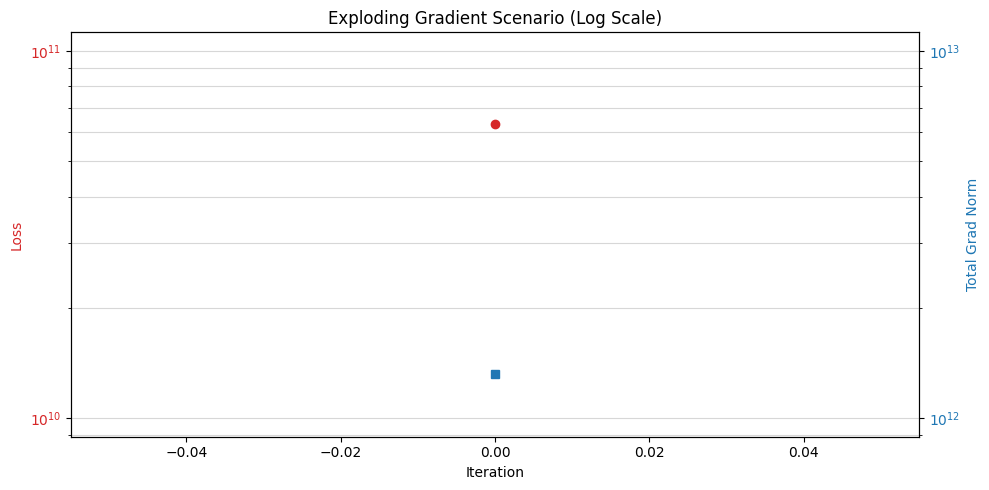

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

class ExplodingNet(nn.Module):
    def __init__(self, input_size=20, hidden_layers=10, hidden_size=64):
        super().__init__()
        self.layers = nn.ModuleList()
        last_dim = input_size
        for _ in range(hidden_layers):
            layer = nn.Linear(last_dim, hidden_size)
            nn.init.xavier_normal_(layer.weight)
            layer.weight.data *= 5.0
            self.layers.append(layer)
            last_dim = hidden_size
        self.output_layer = nn.Linear(hidden_size, 1)
        self.activation = nn.ReLU()

    def forward(self, x):
        for layer in self.layers:
            x = self.activation(layer(x))
        return self.output_layer(x)
torch.manual_seed(42)
X = torch.randn(100, 20)
y = torch.randn(100, 1)

model = ExplodingNet()
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss_history = []
grad_norm_history = []

print(f"{'Iteration':<12} | {'Total Grad Norm':<15} | {'Loss':<10}")
print("-" * 45)

for i in range(1, 6):
    outputs = model(X)
    loss = criterion(outputs, y)
    optimizer.zero_grad()
    loss.backward()
    total_norm = 0
    for p in model.parameters():
        if p.grad is not None:
            param_norm = p.grad.data.norm(2)
            total_norm += param_norm.item() ** 2
    total_norm = total_norm ** 0.5
    loss_history.append(loss.item())
    grad_norm_history.append(total_norm)

    print(f"{i:<12} | {total_norm:<15.2f} | {loss.item():<10.2f}")

    optimizer.step()

    if torch.isnan(torch.tensor(loss.item())):
        print("\n[!] Gradient Exploded: Loss is now NaN.")
# fig, ax1 = plt.subplots(figsize=(10, 5))

# color = 'tab:red'
# ax1.set_xlabel('Iteration')
# ax1.set_ylabel('Loss', color=color)
# ax1.plot(loss_history, color=color, marker='o', label='Loss')
# ax1.tick_params(axis='y', labelcolor=color)
# ax1.set_yscale('log')

# ax2 = ax1.twinx()
# color = 'tab:blue'
# ax2.set_ylabel('Total Grad Norm', color=color)
# ax2.plot(grad_norm_history, color=color, marker='s', label='Grad Norm')
# ax2.tick_params(axis='y', labelcolor=color)
# ax2.set_yscale('log')

plt.plot()
plt.title('Exploding Gradient Scenario (Log Scale)')
fig.tight_layout()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()
